# Módulo 4 — Teoría y demostraciones

Notebook de apoyo para la teoría de los **Días 6 y 7** (ver
[`README.md`](../README.md)).

> **Nota sobre los datos usados:** a partir de este módulo trabajamos con
> un `wrfout` **real**, no sintético — una salida real del WRF V4.7.1
> (proyecto *bigua*), recortada a variables de superficie + el nivel más
> bajo de U/V para que el archivo sea manejable (`data/grid_muestra/`,
> ~44 MB; los archivos completos originales pesan ~1 GB cada uno y quedan
> fuera del repositorio). El dominio real cubre **Argentina/Uruguay/sur de
> Brasil** (no Perú) — el dominio del proyecto que generó estos datos —,
> pero eso no afecta nada de lo que enseña este módulo: la estructura de
> un `wrfout`, la grilla staggered, la proyección y la precipitación
> acumulada son universales a cualquier corrida del WRF, sin importar el
> dominio. Los tres pasos de tiempo disponibles están espaciados **cada 2
> horas** (06, 08 y 10 UTC del 2024-12-13), no cada hora — un detalle real
> que hay que verificar siempre, no asumir (retomado en la Sección 4).

## Sección 1 — Por qué wrfout no es un NetCDF "normal"

Abrimos el archivo real **antes** de aplicar `xwrf`, para ver la
estructura cruda tal como sale del modelo.

In [1]:
import xarray as xr

raw = xr.open_dataset("../../../data/grid_muestra/wrfout_real_muestra.nc")
print(raw)

/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<xarray.Dataset> Size: 141MB
Dimensions:   (Time: 3, south_north: 786, west_east: 879, bottom_top: 1,
               west_east_stag: 880, south_north_stag: 787)
Coordinates:
    XTIME     (Time) datetime64[ns] 24B ...
    XLAT      (Time, south_north, west_east) float32 8MB ...
    XLONG     (Time, south_north, west_east) float32 8MB ...
    XLAT_V    (Time, south_north_stag, west_east) float32 8MB ...
    XLONG_V   (Time, south_north_stag, west_east) float32 8MB ...
    XLAT_U    (Time, south_north, west_east_stag) float32 8MB ...
    XLONG_U   (Time, south_north, west_east_stag) float32 8MB ...
Dimensions without coordinates: Time, south_north, west_east, bottom_top,
                                west_east_stag, south_north_stag
Data variables:
    Times     (Time) |S19 57B ...
    T2        (Time, south_north, west_east) float32 8MB ...
    U10       (Time, south_north, west_east) float32 8MB ...
    V10       (Time, south_north, west_east) float32 8MB ...
    PSFC      (Time, sou

In [2]:
print("Dimensiones de T2 (variable de masa):", raw['T2'].dims, raw['T2'].shape)
print("Dimensiones de U   (viento, staggered en X):", raw['U'].dims, raw['U'].shape)
print("Dimensiones de V   (viento, staggered en Y):", raw['V'].dims, raw['V'].shape)
print()
print("Nótese: west_east_stag tiene", raw.sizes['west_east_stag'],
      "puntos, un punto más que west_east (", raw.sizes['west_east'], ") —",
      "la grilla Arakawa-C desplaza U medio punto respecto a las variables de masa.",
      "Esto es una corrida real: el desplazamiento no es un artefacto del generador",
      "sintético, es así como el WRF resuelve sus ecuaciones siempre.")

Dimensiones de T2 (variable de masa): ('Time', 'south_north', 'west_east') (3, 786, 879)
Dimensiones de U   (viento, staggered en X): ('Time', 'bottom_top', 'south_north', 'west_east_stag') (3, 1, 786, 880)
Dimensiones de V   (viento, staggered en Y): ('Time', 'bottom_top', 'south_north_stag', 'west_east') (3, 1, 787, 879)

Nótese: west_east_stag tiene 880 puntos, un punto más que west_east ( 879 ) — la grilla Arakawa-C desplaza U medio punto respecto a las variables de masa. Esto es una corrida real: el desplazamiento no es un artefacto del generador sintético, es así como el WRF resuelve sus ecuaciones siempre.


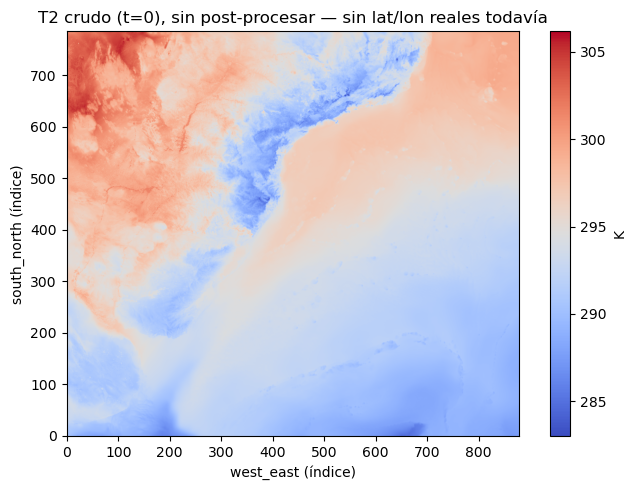

In [4]:
import matplotlib.pyplot as plt

# Antes de xwrf, T2 todavía no tiene coordenadas lat/lon utilizables --
# se grafica con imshow, por índice de fila/columna, no por lat/lon real
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(raw["T2"].isel(Time=0).values, origin="lower", cmap="coolwarm")
ax.set_xlabel("west_east (índice)")
ax.set_ylabel("south_north (índice)")
ax.set_title("T2 crudo (t=0), sin post-procesar — sin lat/lon reales todavía")
plt.colorbar(im, ax=ax, label="K")
fig.tight_layout()
plt.show()

In [5]:
print("XLAT es 2D:", raw['XLAT'].dims, raw['XLAT'].shape)
print("¿La latitud es constante a lo largo de una fila (como en un lat/lon regular)?")
print("  fila 0:  ", raw['XLAT'].isel(Time=0, south_north=0).values[:5].round(3))
print("  fila 400:", raw['XLAT'].isel(Time=0, south_north=400).values[:5].round(3))
print("-> Varían ligeramente incluso dentro de la misma fila: la grilla real está",
      "en una proyección cartográfica (Mercator, en este caso), no es un rectángulo",
      "regular de lat/lon.")

XLAT es 2D: ('Time', 'south_north', 'west_east') (3, 786, 879)
¿La latitud es constante a lo largo de una fila (como en un lat/lon regular)?
  fila 0:   [-39.466 -39.466 -39.466 -39.466 -39.466]
  fila 400: [-29.497 -29.497 -29.497 -29.497 -29.497]
-> Varían ligeramente incluso dentro de la misma fila: la grilla real está en una proyección cartográfica (Mercator, en este caso), no es un rectángulo regular de lat/lon.


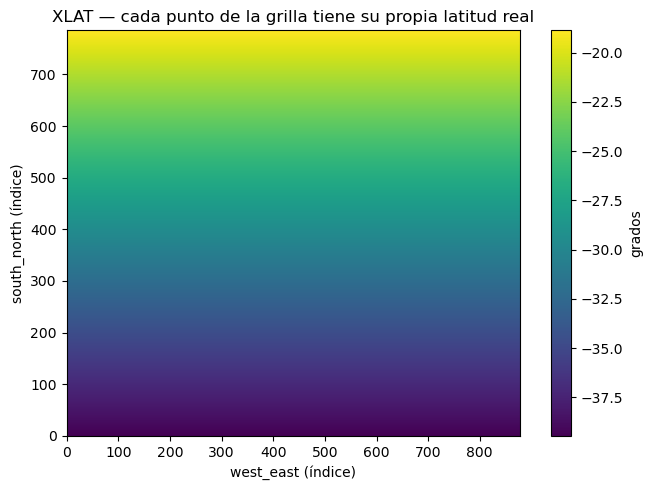

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(raw["XLAT"].isel(Time=0).values, origin="lower", cmap="viridis")
ax.set_xlabel("west_east (índice)")
ax.set_ylabel("south_north (índice)")
ax.set_title("XLAT — cada punto de la grilla tiene su propia latitud real")
plt.colorbar(im, ax=ax, label="grados")
fig.tight_layout()
plt.show()

## Sección 2 — El rol de xwrf: destagger + proyección + variables físicas

In [7]:
import xwrf

ds = raw.xwrf.postprocess().xwrf.destagger()
print(ds)

<xarray.Dataset> Size: 141MB
Dimensions:         (Time: 3, y: 786, x: 879, z: 1, x_stag: 880, y_stag: 787)
Coordinates:
  * Time            (Time) datetime64[us] 24B 2024-12-13T06:00:00 ... 2024-12...
    XTIME           (Time) datetime64[ns] 24B ...
  * y               (y) float64 6kB -4.258e+06 -4.255e+06 ... -1.903e+06
  * x               (x) float64 7kB -1.317e+06 -1.314e+06 ... 1.317e+06
    XLAT            (y, x) float32 3MB -39.47 -39.47 -39.47 ... -18.87 -18.87
    XLONG           (y, x) float32 3MB -61.2 -61.17 -61.14 ... -34.61 -34.58
    XLAT_V          (y_stag, x) float32 3MB -39.48 -39.48 ... -18.86 -18.86
    XLONG_V         (y_stag, x) float32 3MB -61.2 -61.17 ... -34.61 -34.58
  * x_stag          (x_stag) float64 7kB -1.319e+06 -1.316e+06 ... 1.318e+06
    XLAT_U          (y, x_stag) float32 3MB -39.47 -39.47 ... -18.87 -18.87
    XLONG_U         (y, x_stag) float32 3MB -61.21 -61.18 ... -34.6 -34.57
  * y_stag          (y_stag) float64 6kB -4.259e+06 -4.256e+06 ... -1.

In [9]:
print("Después de xwrf: dimensiones de U:", ds['U'].dims, ds['U'].shape)
print("(mismas dimensiones que T2 ahora — ya no está desplazado)")
print()
print("CRS detectado automáticamente por xwrf a partir de los atributos globales:")
print(ds['wrf_projection'].item())
print()
print("MAP_PROJ real =", raw.attrs['MAP_PROJ'], "-> 3 = Mercator",
      "(el ejemplo sintético del curso usaba 1 = Lambert Conformal;",
      "xwrf reconoce ambas proyecciones automáticamente, como se ve aquí).")

Después de xwrf: dimensiones de U: ('Time', 'z', 'y', 'x') (3, 1, 786, 879)
(mismas dimensiones que T2 ahora — ya no está desplazado)

CRS detectado automáticamente por xwrf a partir de los atributos globales:
+proj=merc +x_0=0 +y_0=0 +a=6370000 +b=6370000 +lon_0=-47.889381408691406 +lat_ts=-27.097000122070312 +type=crs

MAP_PROJ real = 3 -> 3 = Mercator (el ejemplo sintético del curso usaba 1 = Lambert Conformal; xwrf reconoce ambas proyecciones automáticamente, como se ve aquí).


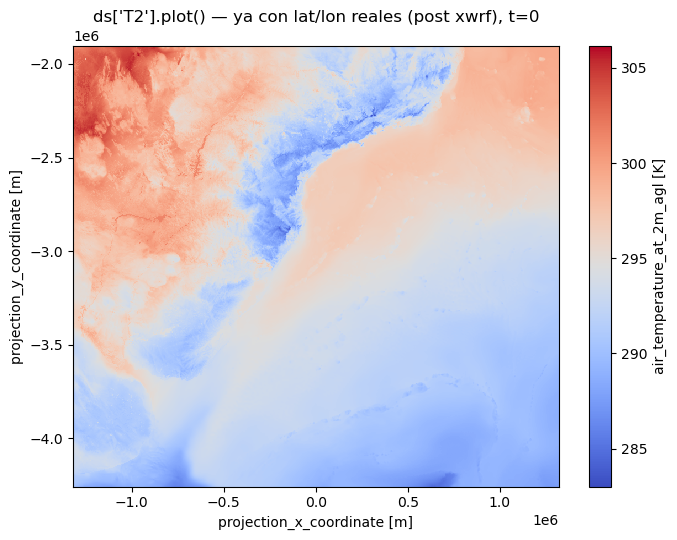

In [10]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ds["T2"].isel(Time=0).plot(ax=ax, cmap="coolwarm")
ax.set_title("ds['T2'].plot() — ya con lat/lon reales (post xwrf), t=0")
fig.tight_layout()
plt.show()

## Sección 3 — Vientos: grid-relative vs. earth-relative

`U10`/`V10` crudos están relativos a los **ejes de la grilla** del modelo,
no a norte/este geográfico real. `xwrf` calcula automáticamente
`wind_east_10`/`wind_north_10` (earth-relative) usando `SINALPHA`/`COSALPHA`
(el ángulo de rotación de la grilla respecto al norte verdadero).

In [9]:
import numpy as np

diferencia = float(np.abs(ds["U10"] - ds["wind_east_10"]).max())
print(f"Diferencia máxima entre U10 (grid-relative) y wind_east_10 (earth-relative): {diferencia:.4f} m/s")
print()
print("En este dominio real la diferencia es EXACTAMENTE cero en todas partes —",
      "y no es casualidad: la proyección Mercator es conforme y mantiene el norte",
      "de la grilla igual al norte geográfico real en todo el dominio (por eso se usa",
      "para cartas de navegación). Esto es distinto de Lambert Conformal (el ejemplo",
      "sintético del curso), donde la rotación SÍ varía con la distancia a la longitud",
      "estándar. Ambos comportamientos son correctos: dependen de la proyección elegida",
      "al configurar el dominio del WRF, no de si el dato es real o sintético.")

Diferencia máxima entre U10 (grid-relative) y wind_east_10 (earth-relative): 0.0000 m/s

En este dominio real la diferencia es EXACTAMENTE cero en todas partes — y no es casualidad: la proyección Mercator es conforme y mantiene el norte de la grilla igual al norte geográfico real en todo el dominio (por eso se usa para cartas de navegación). Esto es distinto de Lambert Conformal (el ejemplo sintético del curso), donde la rotación SÍ varía con la distancia a la longitud estándar. Ambos comportamientos son correctos: dependen de la proyección elegida al configurar el dominio del WRF, no de si el dato es real o sintético.


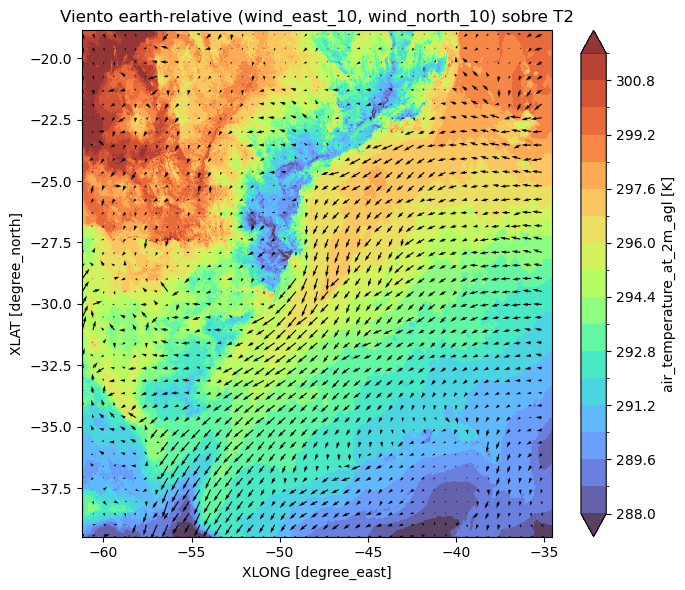

In [20]:
# Un subsampleo de la grilla para que las flechas de viento sean legibles.
# Se fuerza x=XLONG, y=XLAT (grados) para que coincidan con las coordenadas
# usadas por quiver -- por defecto .plot() usaria projection_x/y_coordinate (metros).
paso = 20
fig, ax = plt.subplots(figsize=(7, 6))
ds["T2"].isel(Time=2).plot(ax=ax, x="XLONG", y="XLAT", cmap="turbo", extend='both', 
                           alpha=0.8, add_colorbar=True, robust=True,levels=21)
ax.quiver(
    ds["XLONG"].isel(y=slice(None, None, paso), x=slice(None, None, paso)),
    ds["XLAT"].isel(y=slice(None, None, paso), x=slice(None, None, paso)),
    ds["wind_east_10"].isel(Time=0, y=slice(None, None, paso), x=slice(None, None, paso)),
    ds["wind_north_10"].isel(Time=0, y=slice(None, None, paso), x=slice(None, None, paso)),
)
ax.set_title("Viento earth-relative (wind_east_10, wind_north_10) sobre T2")
fig.tight_layout()
plt.show()

## Sección 4 (Día 7) — Precipitación acumulada: el cálculo correcto

In [21]:
import numpy as np

precip_total = ds["RAINC"] + ds["RAINNC"]

print("Tiempos disponibles:", [str(t)[:16] for t in ds['Time'].values])
print("Espaciado entre pasos: 2 horas (no 1) — hay que verificarlo, no asumirlo.")
print()

# INCORRECTO: tratar el acumulado como si fuera el total de un solo intervalo
incorrecto = precip_total.isel(Time=2)

# CORRECTO: diferencia entre pasos de tiempo consecutivos (aquí, un intervalo de 2 h)
correcto = precip_total.diff("Time").isel(Time=1)  # acumulado entre 08:00 y 10:00

print(f"Precipitación 'incorrecta' (acumulado total hasta las 10:00): media = {float(incorrecto.mean()):.3f} mm, máx = {float(incorrecto.max()):.1f} mm")
print(f"Precipitación CORRECTA (acumulada solo entre 08:00 y 10:00): media = {float(correcto.mean()):.3f} mm, máx = {float(correcto.max()):.1f} mm")
print()
print("¿El acumulado total es siempre >= la diferencia por intervalo?",
      bool((incorrecto.values >= correcto.values).all()))
print()
print("Nótese además que, como el paso es de 2 horas y no 1, 'correcto' aquí es",
      "precipitación acumulada EN 2 HORAS, no una tasa horaria — para obtener mm/h",
      "habría que dividir entre 2. Este archivo real no tiene resolución horaria.")

Tiempos disponibles: ['2024-12-13T06:00', '2024-12-13T08:00', '2024-12-13T10:00']
Espaciado entre pasos: 2 horas (no 1) — hay que verificarlo, no asumirlo.

Precipitación 'incorrecta' (acumulado total hasta las 10:00): media = 3.616 mm, máx = 383.9 mm
Precipitación CORRECTA (acumulada solo entre 08:00 y 10:00): media = 0.776 mm, máx = 180.9 mm

¿El acumulado total es siempre >= la diferencia por intervalo? True

Nótese además que, como el paso es de 2 horas y no 1, 'correcto' aquí es precipitación acumulada EN 2 HORAS, no una tasa horaria — para obtener mm/h habría que dividir entre 2. Este archivo real no tiene resolución horaria.


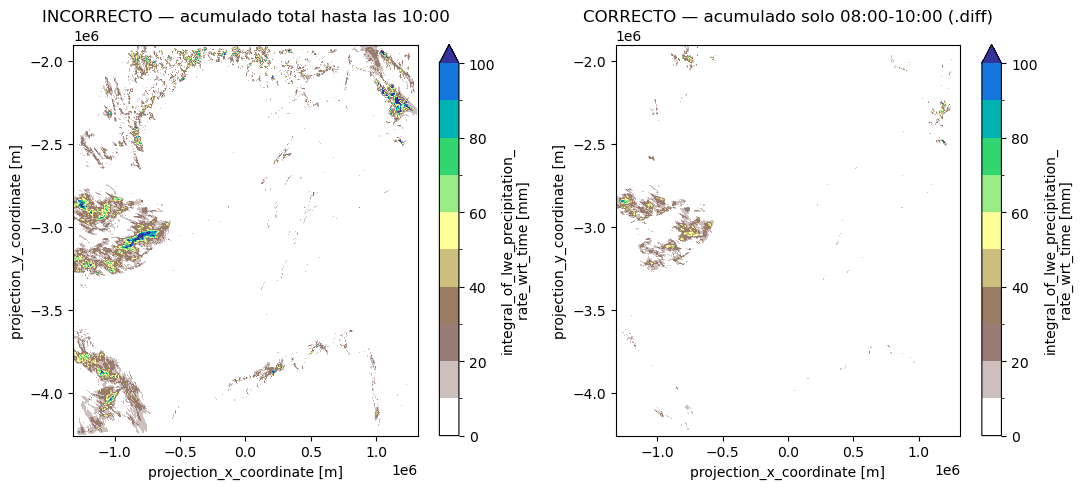

In [26]:
vmax = float(max(incorrecto.max(), correcto.max()))
vmax = 100
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
incorrecto.plot(ax=axes[0], cmap="terrain_r", vmin=0, vmax=vmax,levels=11)
axes[0].set_title("INCORRECTO — acumulado total hasta las 10:00")
correcto.plot(ax=axes[1], cmap="terrain_r", vmin=0, vmax=vmax,levels=11)
axes[1].set_title("CORRECTO — acumulado solo 08:00-10:00 (.diff)")
fig.tight_layout()
plt.show()

---
Continuar con
[`02_practica_dia6_mapas.ipynb`](02_practica_dia6_mapas.ipynb).